# TinyML on the ESP32 training, testing and exporting 9 models

## 1. Setup and configuration

In [269]:
import os, json, time, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay,roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras

SEED = 42
N_FEATURES = 20 # featreus kept after feature selection
DATA_FILE = Path("data/train_test_network.csv")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

ESP32_DIR = Path("esp32")

N_DEVICE_TEST = 400
N_SERIAL_TEST = 2000
ANOMALY_PERCENTILE = 95.0

NN_EPOCHS      = 30
NN_BATCH       = 256

np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)


## 2. Load the TON_IoT network dataset

In [270]:
df = pd.read_csv(DATA_FILE, low_memory=False)

print(df.shape)
display(df.head())
print("\nlabel:\n", df["label"].value_counts())
print("\ntype:\n", df["type"].value_counts())

(211043, 44)


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor



label:
 label
1    161043
0     50000
Name: count, dtype: int64

type:
 type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
ransomware    20000
scanning      20000
xss           20000
mitm           1043
Name: count, dtype: int64


## 3. Preprocessing

In [271]:
# Columns we throw away:
#   - IP addresses and source port say WHICH machine, not WHAT it does
#   - dns_query is free text (thousands of different domain names)
DROP_COLUMNS = ["ts", "src_ip", "dst_ip", "src_port", "dns_query"]

LABEL_COLUMNS = ["label", "type"]

# Columns that contain words instead of numbers (e.g. "tcp", "udp")
TEXT_COLUMNS = ["proto", "service", "conn_state",
                "dns_AA", "dns_RD", "dns_RA", "dns_rejected",
                "ssl_version", "ssl_cipher", "ssl_resumed", "ssl_established",
                "ssl_subject", "ssl_issuer",
                "http_method", "http_uri", "http_user_agent",
                "http_orig_mime_types", "http_resp_mime_types",
                "weird_name", "weird_notice"]

NUMBER_COLUMNS = [col for col in df.columns if col not in DROP_COLUMNS + LABEL_COLUMNS + TEXT_COLUMNS]

X_raw = pd.DataFrame()

# Number columns: "-" means "no value", so we use 0
for col in NUMBER_COLUMNS:
    X_raw[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# Text columns: give every word a number
# "-" always gets 0, the other words get 1, 2, 3 ... (alphabetical)
# e.g. proto: "-" -> 0, "icmp" -> 1, "tcp" -> 2, "udp" -> 3
encodings = {}  # saved so the ESP32 / gateway can use the same numbers
for col in TEXT_COLUMNS:
    text = df[col].fillna("-").astype(str).str.strip()
    words = sorted(set(text) - {"-"})
    mapping = {"-": 0}
    for number, word in enumerate(words, start=1):
        mapping[word] = number
    X_raw[col] = text.map(mapping)
    encodings[col] = mapping


# Remove columns that have the same value in every row
useless = [col for col in X_raw.columns if X_raw[col].nunique() == 1]
X_raw = X_raw.drop(columns=useless)

# put the columns back in the same order as in the CSV file
X_raw = X_raw[[col for col in df.columns if col in X_raw.columns]]

numeric_cols     = [col for col in NUMBER_COLUMNS if col not in useless]
categorical_cols = [col for col in TEXT_COLUMNS if col not in useless]
print("number columns:", numeric_cols)
print("text columns  :", categorical_cols)
print("removed (same value everywhere):", useless)

y_binary = df["label"].to_numpy()

CLASS_NAMES = ["normal", "attack"]
y_task = y_binary

N_CLASSES = len(CLASS_NAMES)

# Remove duplicate rows (same features AND same label)
rows = X_raw.copy()
rows["y_task"] = y_task
rows["y_binary"] = y_binary
keep = (~rows.duplicated()).to_numpy()

X_raw    = X_raw[keep].reset_index(drop=True)
y_task   = y_task[keep]
y_binary = y_binary[keep]
print(f"\nremoved {(~keep).sum()} duplicates, {len(X_raw)} rows left")

print(pd.Series(y_task).map({0: "normal", 1: "attack"}).value_counts())

number columns: ['dst_port', 'duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'http_trans_depth', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'weird_addl']
text columns  : ['proto', 'service', 'conn_state', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_method', 'http_uri', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_notice']
removed (same value everywhere): []

removed 105849 duplicates, 105194 rows left
attack    81088
normal    24106
Name: count, dtype: int64


### Train / validation / test split, scaling and feature selection
* Stratified **70 / 15 / 15** split.
* **log1p** on heavy-tailed columns (bytes, packets, durations: numeric columns with max > 100). Then **z-score standardisation**, with the statistics computed on the training set only.
* **Feature selection**: the `N_FEATURES` most important features according to an Extra-Trees model trained on the training set. Fewer features means less memory and faster inference on the MCU.

train 73635 | val 15779 | test 15780


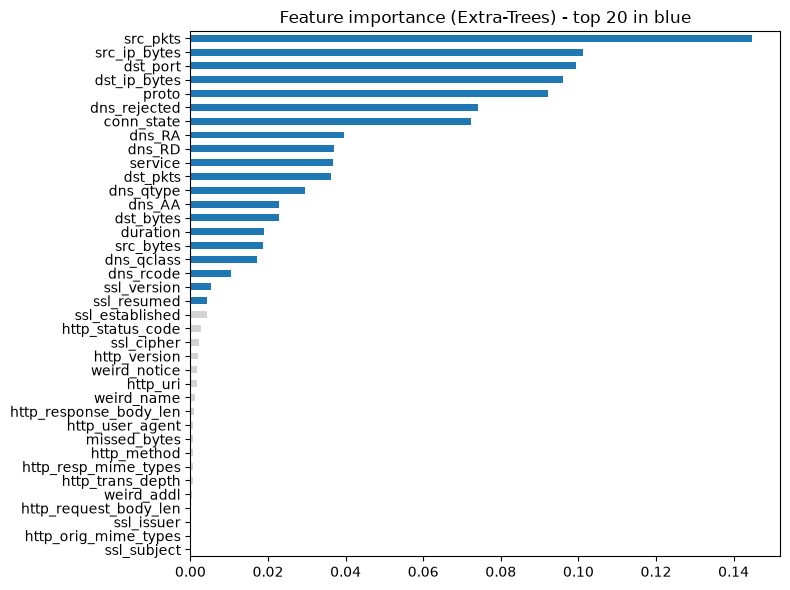

selected features: ['src_pkts', 'src_ip_bytes', 'dst_port', 'dst_ip_bytes', 'proto', 'dns_rejected', 'conn_state', 'dns_RA', 'dns_RD', 'service', 'dst_pkts', 'dns_qtype', 'dns_AA', 'dst_bytes', 'duration', 'src_bytes', 'dns_qclass', 'dns_rcode', 'ssl_version', 'ssl_resumed']


In [272]:
idx = np.arange(len(X_raw))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y_task, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y_task[idx_tmp], random_state=SEED)
print(f"train {len(idx_train)} | val {len(idx_val)} | test {len(idx_test)}")

all_cols = list(X_raw.columns)
log_cols = [c for c in numeric_cols if X_raw.loc[idx_train, c].max() > 100]

def transform_log(X: pd.DataFrame, cols) -> pd.DataFrame:
    X = X.copy()
    for c in cols:
        X[c] = np.log1p(np.clip(X[c].values, 0, None))
    return X

Xl_train = transform_log(X_raw.loc[idx_train], log_cols)
mean_all = Xl_train.mean()
std_all = Xl_train.std(ddof=0).replace(0, 1.0)

# feature importance on a (sub)sample of the training data
sub = np.random.RandomState(SEED).choice(len(idx_train), min(100_000, len(idx_train)), replace=False)
et = ExtraTreesClassifier(n_estimators=300, max_depth=16, n_jobs=-1, random_state=SEED)
et.fit(((Xl_train - mean_all) / std_all).values[sub], y_task[idx_train][sub])
importance = pd.Series(et.feature_importances_, index=all_cols).sort_values(ascending=False)
SELECTED = list(importance.index[:N_FEATURES])

fig, ax = plt.subplots(figsize=(8, 6))
importance.iloc[::-1].plot.barh(ax=ax, color=["tab:blue" if c in SELECTED else "lightgray" for c in importance.index[::-1]])
ax.set_title(f"Feature importance (Extra-Trees) - top {N_FEATURES} in blue")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "feature_importance.png", dpi=150); plt.show()
print("selected features:", SELECTED)

In [273]:
FEAT_LOG  = np.array([c in log_cols for c in SELECTED], dtype=np.uint8)
FEAT_MEAN = mean_all[SELECTED].to_numpy(dtype=np.float64)
FEAT_STD  = std_all[SELECTED].to_numpy(dtype=np.float64)

def preprocess(raw: np.ndarray) -> np.ndarray:
    """Same as preprocess() in main/preprocess.h on the ESP32."""
    x = raw.astype(np.float64).copy()
    x[:, FEAT_LOG == 1] = np.log1p(np.clip(x[:, FEAT_LOG == 1], 0, None))
    return ((x - FEAT_MEAN) / FEAT_STD).astype(np.float32)

R_train = X_raw.loc[idx_train, SELECTED].to_numpy(dtype=np.float32)
R_val   = X_raw.loc[idx_val,   SELECTED].to_numpy(dtype=np.float32)
R_test  = X_raw.loc[idx_test,  SELECTED].to_numpy(dtype=np.float32)
X_train, X_val, X_test = preprocess(R_train), preprocess(R_val), preprocess(R_test)
y_train, y_val, y_test = y_task[idx_train], y_task[idx_val], y_task[idx_test]
yb_train, yb_val, yb_test = y_binary[idx_train], y_binary[idx_val], y_binary[idx_test]

class_weights = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(class_weights)}
print(X_train.shape, X_val.shape, X_test.shape)

(73635, 20) (15779, 20) (15780, 20)


## 4. Helper functions

In [274]:
results = []        # one row per model -> becomes the comparison table
predictions = {}    # stored predictions -> used for the confusion matrices

def evaluate(name, y_true, y_pred, train_time_s, predict_fn, size_bytes, extra=None):
    """Compute the scores of one model and store them in `results`."""
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0)   # scores for the "attack" class

    # how long does one prediction take on this PC? (average over 2000 samples)
    start = time.perf_counter()
    predict_fn(X_test[:2000])
    pc_time_us = (time.perf_counter() - start) / 2000 * 1e6

    row = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "size_kb": size_bytes / 1024,      # size of the model on the ESP32
        "pc_infer_us": pc_time_us,
        "train_time_s": train_time_s,
    }
    if extra:                              # optional extra info, e.g. number of tree nodes
        row.update(extra)

    # replace an older result of the same model (if the cell is run twice)
    results[:] = [r for r in results if r["model"] != name]
    results.append(row)
    predictions[name] = (y_true, y_pred)

    print(f"{name}: accuracy={row['accuracy']:.4f}  precision={precision:.4f}  "
          f"recall={recall:.4f}  F1={f1:.4f}  size={row['size_kb']:.1f} KB")


def plot_confusion_matrix(name):
    """Show the confusion matrix of a model that was evaluated before."""
    y_true, y_pred = predictions[name]
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(colorbar=False)
    plt.title(name)
    plt.show()

def c_float(value):
    """Write a number as a C float, e.g. 0.5 -> '0.5f' and 3 -> '3.0f'."""
    text = "%.9g" % float(np.float32(value))   # 9 digits = exact float32 value
    if "." not in text and "e" not in text:
        text += ".0"                            # '3f' is not valid C, '3.0f' is
    return text + "f"

def c_array(name, values, c_type, per_line=10, align=False):
    """Turn a list/array of numbers into a C array, e.g.
       static const float W[3] = { 0.1f, 0.2f, 0.3f };"""
    values = np.asarray(values).ravel()                      # make it 1-D
    if c_type == "float":
        items = [c_float(v) for v in values]
    else:
        items = [str(int(v)) for v in values]

    lines = []
    for i in range(0, len(items), per_line):                # a few numbers per line
        lines.append(", ".join(items[i:i + per_line]))
    body = ",\n    ".join(lines)

    prefix = "alignas(16) " if align else ""                # TFLite models must be aligned
    return f"{prefix}static const {c_type} {name}[{len(values)}] = {{\n    {body}\n}};\n"

def c_int_type(largest_value):
    """Smallest integer type that fits: int16_t saves flash compared to int32_t."""
    return "int16_t" if largest_value < 32767 else "int32_t"

def c_header(title):
    """Text at the top of every generated .h file."""
    return (f"// {title}\n"
            f"// GENERATED by TinyML_models.ipynb - do not edit by hand.\n"
            f"#pragma once\n#include <stdint.h>\n\n")

def write_file(path, text):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text)

def pick_test_samples(y, n, seed=SEED):
    """Pick n test rows with the same normal/attack ratio as the test set."""
    rows = np.arange(len(y))
    if n >= len(y):
        return rows
    chosen, _ = train_test_split(rows, train_size=n, stratify=y, random_state=seed)
    return np.sort(chosen)

def export_project(folder, model_name, model_data_h, y_pred):
    """Write the 4 generated .h files + test_set.csv into esp32/<folder>.

    model_data_h : C code with the model parameters (made by the model's own cell)
    y_pred       : the Python model's predictions on X_test (to check the C port)
    """
    main = ESP32_DIR / folder / "main"

    # 1) preprocessing: which features, log yes/no, mean and 1/std
    names = ",\n    ".join(f'"{c}"' for c in SELECTED)
    text = c_header("Preprocessing parameters")
    text += f"#define N_FEATURES {N_FEATURES}\n\n"
    text += f"static const char *const FEATURE_NAMES[N_FEATURES] = {{\n    {names}\n}};\n\n"
    text += "// Integer codes of the text features (0 = '-'):\n"
    for col in SELECTED:
        if col in encodings:
            codes = ", ".join(f"{word}={number}" for word, number in list(encodings[col].items())[:30])
            text += f"//   {col}: {codes}\n"
    text += "\n"
    text += c_array("FEATURE_LOG1P", FEAT_LOG, "uint8_t", per_line=20)
    text += c_array("FEATURE_MEAN", FEAT_MEAN, "float")
    text += c_array("FEATURE_INV_STD", 1.0 / FEAT_STD, "float")
    write_file(main / "preprocess_data.h", text)

    # 2) model info: name and class names
    text = c_header("Model information")
    text += f'#define MODEL_NAME "{model_name}"\n'
    text += f"#define MODEL_N_CLASSES {N_CLASSES}\n"
    text += f"#define N_FEATURES_MODEL {N_FEATURES}\n"
    text += "static const char *const MODEL_CLASS_NAMES[MODEL_N_CLASSES] = {"
    text += ", ".join(f'"{c}"' for c in CLASS_NAMES) + "};\n"
    write_file(main / "model_info.h", text)

    # 3) model parameters (already written as C code by the model's cell)
    write_file(main / "model_data.h", c_header(f"{model_name} parameters") + model_data_h)

    # 4) test samples for the self-test: RAW values, true label, Python prediction
    sel = pick_test_samples(y_test, N_DEVICE_TEST)
    rows = ",\n".join("    {" + ", ".join(c_float(v) for v in R_test[i]) + "}" for i in sel)
    text = c_header("Test samples for the on-device self-test (RAW features)")
    text += f"#define N_TEST {len(sel)}\n\n"
    text += f"static const float TEST_X[N_TEST][{N_FEATURES}] = {{\n{rows}\n}};\n\n"
    text += c_array("TEST_Y", y_test[sel], "uint8_t", per_line=25)
    text += "// prediction of the Python model for the same samples\n"
    text += c_array("TEST_PY_PRED", y_pred[sel], "uint8_t", per_line=25)
    write_file(main / "test_data.h", text)

    # 5) bigger test set as CSV for tools/serial_eval.py
    sel = pick_test_samples(y_test, N_SERIAL_TEST, seed=SEED + 1)
    table = pd.DataFrame(R_test[sel], columns=SELECTED)
    table["label"] = y_test[sel]
    table["python_pred"] = y_pred[sel]
    table.to_csv(ESP32_DIR / folder / "test_set.csv", index=False)

    print(f"  -> exported to {ESP32_DIR / folder}")

# save the preprocessing + text codes once, for a gateway / other programs
ESP32_DIR.mkdir(exist_ok=True)
with open(ESP32_DIR / "feature_encoding.json", "w") as f:
    json.dump({"features": SELECTED,
               "log1p": FEAT_LOG.tolist(),
               "mean": FEAT_MEAN.tolist(),
               "std": FEAT_STD.tolist(),
               "categorical_encodings": {c: encodings[c] for c in SELECTED if c in encodings},
               "classes": CLASS_NAMES}, f, indent=2)
print("wrote", ESP32_DIR / "feature_encoding.json")

wrote esp32/feature_encoding.json


### 5.1 Decision Tree 

Decision Tree: accuracy=0.9970  precision=0.9984  recall=0.9977  F1=0.9980  size=3.5 KB


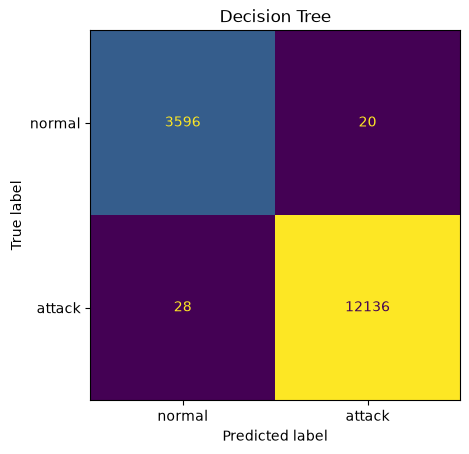

  -> exported to esp32/01_decision_tree


In [275]:
start = time.perf_counter()
dt = DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, class_weight="balanced", random_state=SEED)

dt.fit(X_train, y_train)
dt_time = time.perf_counter() - start

y_pred = dt.predict(X_test)

tree = dt.tree_
feature = tree.feature.copy()
feature[feature < 0] = -1
threshold = tree.threshold
is_leaf = feature == -1

counts = tree.value[:, 0, :]
proba = counts / counts.sum(axis=1, keepdims=True)
leaf_class = proba.argmax(axis=1)
leaf_prob = np.where(is_leaf, proba.max(axis=1), 0.0)

left  = np.where(is_leaf, leaf_class, tree.children_left)
right = np.where(is_leaf, 0, tree.children_right)

index_type = c_int_type(len(feature))             # int16_t if the tree is small enough

dt_h  = f"#define DT_N_NODES {len(feature)}\n\n"
dt_h += c_array("DT_FEATURE",   feature,   "int16_t", per_line=20)
dt_h += c_array("DT_THRESHOLD", threshold, "float")
dt_h += c_array("DT_LEFT",      left,      index_type, per_line=20)
dt_h += c_array("DT_RIGHT",     right,     index_type, per_line=20)
dt_h += c_array("DT_LEAF_PROB", leaf_prob, "float")

index_bytes = 2 if index_type == "int16_t" else 4
dt_size = len(feature) * (2 + 4 + index_bytes + index_bytes + 4)   # feature, threshold, left, right, prob

evaluate("Decision Tree", y_test, y_pred, dt_time, dt.predict, dt_size, extra={"n_nodes": tree.node_count, "depth": dt.get_depth()})
plot_confusion_matrix("Decision Tree")

export_project("01_decision_tree", "DecisionTree", dt_h, y_pred)

### 5.2 Random Forest

Random Forest: accuracy=0.9958  precision=0.9974  recall=0.9972  F1=0.9973  size=29.5 KB


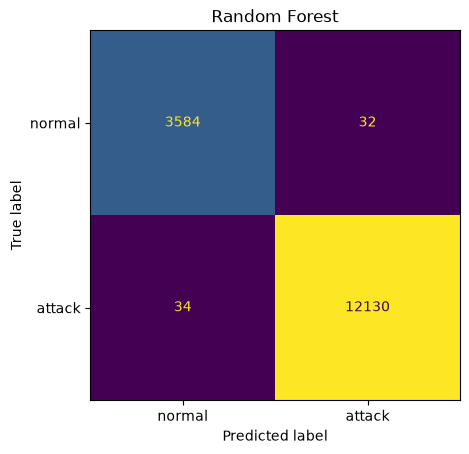

  -> exported to esp32/02_random_forest


In [276]:
start = time.perf_counter()
rf = RandomForestClassifier(n_estimators=10,
                            max_depth=10,
                            min_samples_leaf=5,
                            class_weight="balanced",
                            n_jobs=-1,
                            random_state=SEED)
rf.fit(X_train, y_train)
rf_time = time.perf_counter() - start

y_pred = rf.predict(X_test)


all_feature, all_threshold, all_left, all_right, all_leaf_proba, roots = [], [], [], [], [], []
node_offset = 0      # how many nodes are already in the arrays (from earlier trees)
leaf_offset = 0      # how many leaves are already in leaf_proba

for single_tree in rf.estimators_:
    tree = single_tree.tree_
    feature = tree.feature.copy()
    feature[feature < 0] = -1
    is_leaf = feature == -1

    counts = tree.value[:, 0, :]
    proba  = counts / counts.sum(axis=1, keepdims=True)

    leaf_number = np.cumsum(is_leaf) - 1 + leaf_offset

    left  = np.where(is_leaf, leaf_number, tree.children_left + node_offset)
    right = np.where(is_leaf, 0,           tree.children_right + node_offset)

    roots.append(node_offset)
    all_feature.append(feature)
    all_threshold.append(tree.threshold)
    all_left.append(left)
    all_right.append(right)
    all_leaf_proba.append(proba[is_leaf])

    node_offset += len(feature)
    leaf_offset += is_leaf.sum()

feature    = np.concatenate(all_feature)
threshold  = np.concatenate(all_threshold)
left       = np.concatenate(all_left)
right      = np.concatenate(all_right)
leaf_proba = np.concatenate(all_leaf_proba)

index_type = c_int_type(max(len(feature), leaf_offset))

rf_h  = f"#define RF_N_TREES {len(rf.estimators_)}\n"
rf_h += f"#define RF_N_NODES {len(feature)}\n"
rf_h += f"#define RF_N_LEAVES {leaf_offset}\n\n"
rf_h += c_array("RF_ROOT",       roots,      "int32_t", per_line=20)
rf_h += c_array("RF_FEATURE",    feature,    "int16_t", per_line=20)
rf_h += c_array("RF_THRESHOLD",  threshold,  "float")
rf_h += c_array("RF_LEFT",       left,       index_type, per_line=20)
rf_h += c_array("RF_RIGHT",      right,      index_type, per_line=20)
rf_h += c_array("RF_LEAF_PROBA", leaf_proba, "float")

index_bytes = 2 if index_type == "int16_t" else 4
rf_size = (len(feature) * (2 + 4 + index_bytes + index_bytes)
           + leaf_proba.size * 4 
           + len(roots) * 4)

evaluate("Random Forest", y_test, y_pred, rf_time, rf.predict, rf_size,
         extra={"n_nodes": len(feature)})
plot_confusion_matrix("Random Forest")

# 4) Write the files into esp32/02_random_forest
export_project("02_random_forest", "RandomForest", rf_h, y_pred)

### 5.3 Logistic Regression 

Logistic Regression: accuracy=0.9782  precision=0.9902  recall=0.9814  F1=0.9858  size=0.1 KB


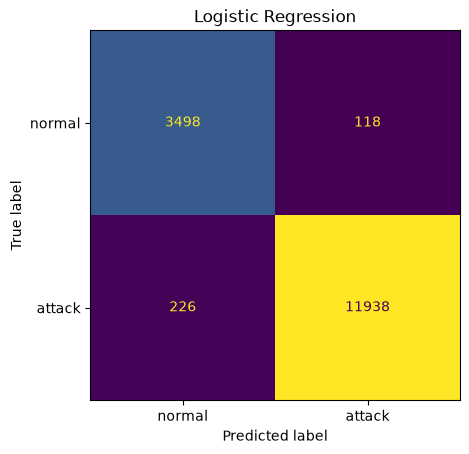

  -> exported to esp32/03_logistic_regression


In [277]:
start = time.perf_counter()
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_train, y_train)
lr_time = time.perf_counter() - start

# 2) Evaluate on the test set
y_pred = lr.predict(X_test)

# 3) Write the weights as C arrays
weights = lr.coef_[0]          # 20 numbers, one per feature
bias    = lr.intercept_        # 1 number

lr_h  = "#define LIN_N_OUT 1\n"     # one output z (binary task)
lr_h += "#define LIN_PROBA 1\n\n"   # 1 = also compute the probability (sigmoid)
lr_h += c_array("LIN_W", weights, "float")
lr_h += c_array("LIN_B", bias, "float")

lr_size = (len(weights) + len(bias)) * 4           # 4 bytes per float

evaluate("Logistic Regression", y_test, y_pred, lr_time, lr.predict, lr_size)
plot_confusion_matrix("Logistic Regression")

# 4) Write the files into esp32/03_logistic_regression
export_project("03_logistic_regression", "LogisticRegression", lr_h, y_pred)

### 5.4 Linear SVM

Linear SVM: accuracy=0.9774  precision=0.9902  recall=0.9804  F1=0.9853  size=0.1 KB


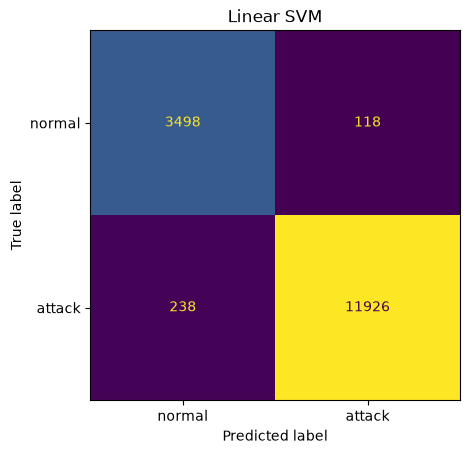

  -> exported to esp32/04_svm


In [278]:
start = time.perf_counter()
svm = LinearSVC(C=1.0,                  # how strongly mistakes are punished
                class_weight="balanced",
                max_iter=5000,
                random_state=SEED)
svm.fit(X_train, y_train)
svm_time = time.perf_counter() - start

# 2) Evaluate on the test set
y_pred = svm.predict(X_test)

# 3) Write the weights as C arrays
weights = svm.coef_[0]
bias    = svm.intercept_

svm_h  = "#define LIN_N_OUT 1\n"
svm_h += "#define LIN_PROBA 0\n\n"      # 0 = an SVM gives no probability, only z
svm_h += c_array("LIN_W", weights, "float")
svm_h += c_array("LIN_B", bias, "float")

svm_size = (len(weights) + len(bias)) * 4

evaluate("Linear SVM", y_test, y_pred, svm_time, svm.predict, svm_size)
plot_confusion_matrix("Linear SVM")

# 4) Write the files into esp32/04_svm
export_project("04_svm", "LinearSVM", svm_h, y_pred)

### 5.4b Kernel SVM

RBF SVM: accuracy=0.9867  precision=0.9968  recall=0.9859  F1=0.9913  size=41.1 KB


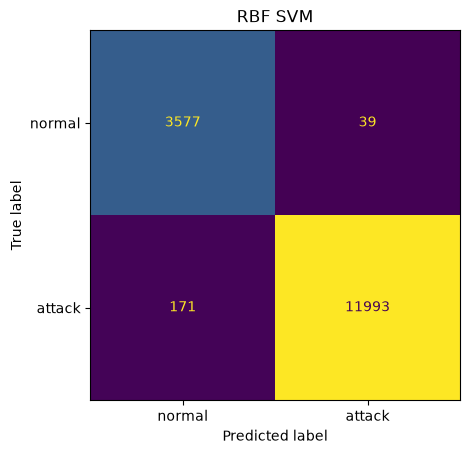

501 support vectors -> 41.1 KB on the ESP32 and 501 kernel calculations per prediction (linear SVM: 84 bytes, 20 multiply-adds)
  -> exported to esp32/04b_svm_rbf


In [279]:
N_SVM_TRAIN = 10_000    # kernel SVMs train slowly (time grows ~ n^2), so use a sample

# 1) Train on a stratified sample of the training data
svm_rows, _ = train_test_split(np.arange(len(X_train)), train_size=N_SVM_TRAIN,
                               stratify=y_train, random_state=SEED)
start = time.perf_counter()
rbf = SVC(kernel="rbf",
          C=1.0,
          gamma="scale",            # width of the "bumps", chosen from the data
          class_weight="balanced")
rbf.fit(X_train[svm_rows], y_train[svm_rows])
rbf_time = time.perf_counter() - start

# 2) Evaluate on the full test set
y_pred = rbf.predict(X_test)

# 3) Write the model as C arrays
support_vectors = rbf.support_vectors_       # (number of SVs) x 20 features
alphas          = rbf.dual_coef_[0]          # one weight per support vector
bias            = rbf.intercept_[0]
gamma           = rbf._gamma                 # the actual number behind gamma="scale"
n_sv            = len(support_vectors)

rbf_h  = f"#define SVM_N_SV {n_sv}\n"
rbf_h += f"static const float SVM_GAMMA = {c_float(gamma)};\n"
rbf_h += f"static const float SVM_B = {c_float(bias)};\n\n"
rbf_h += c_array("SVM_ALPHA", alphas, "float")
rbf_h += c_array("SVM_SV", support_vectors, "float")

rbf_size = (n_sv * N_FEATURES + n_sv + 2) * 4     # support vectors + alphas + gamma + bias

evaluate("RBF SVM", y_test, y_pred, rbf_time, rbf.predict, rbf_size,
         extra={"n_support_vectors": n_sv})
plot_confusion_matrix("RBF SVM")
print(f"{n_sv} support vectors -> {rbf_size/1024:.1f} KB on the ESP32 and {n_sv} "
      f"kernel calculations per prediction (linear SVM: 84 bytes, 20 multiply-adds)")

# 4) Write the files into esp32/04b_svm_rbf
export_project("04b_svm_rbf", "RBF_SVM", rbf_h, y_pred)

### 5.5 Gaussian Naive Bayes

Naive Bayes: accuracy=0.8798  precision=0.9394  recall=0.9023  F1=0.9205  size=0.3 KB


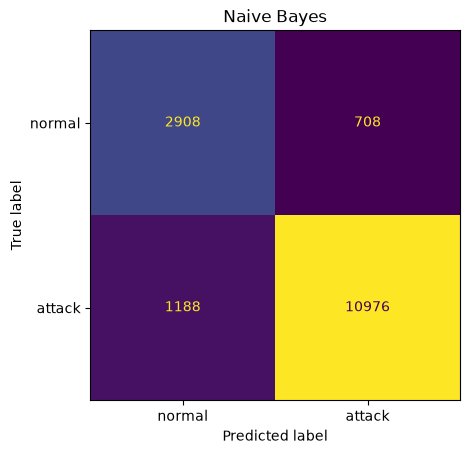

  -> exported to esp32/05_naive_bayes


In [280]:
start = time.perf_counter()
nb = GaussianNB()
nb.fit(X_train, y_train)
nb_time = time.perf_counter() - start

# 2) Evaluate on the test set
y_pred = nb.predict(X_test)

# 3) Write the parameters as C arrays
mean     = nb.theta_          # shape (2 classes, 20 features)
variance = nb.var_            # shape (2 classes, 20 features)
prior    = nb.class_prior_    # how common each class is in the training data

# Score of a class on the ESP32:
#   score = const - 0.5 * sum( (x - mean)^2 / variance )
# The part that does not depend on x is calculated here once:
#   const = log(prior) - 0.5 * sum( log(2 * pi * variance) )
nb_const = np.log(prior) - 0.5 * np.sum(np.log(2.0 * np.pi * variance), axis=1)

nb_h  = c_array("NB_THETA",   mean,           "float")   # means
nb_h += c_array("NB_INV_VAR", 1.0 / variance, "float")   # 1/variance (multiply is faster than divide)
nb_h += c_array("NB_CONST",   nb_const,       "float")

nb_size = (mean.size + variance.size + len(nb_const)) * 4

evaluate("Naive Bayes", y_test, y_pred, nb_time, nb.predict, nb_size)
plot_confusion_matrix("Naive Bayes")

# 4) Write the files into esp32/05_naive_bayes
export_project("05_naive_bayes", "GaussianNB", nb_h, y_pred)

### 5.6 K-Means anomaly detector (unsupervised)

K-Means (anomaly): accuracy=0.9107  precision=0.9841  recall=0.8987  F1=0.9395  size=1.3 KB
ROC-AUC = 0.964


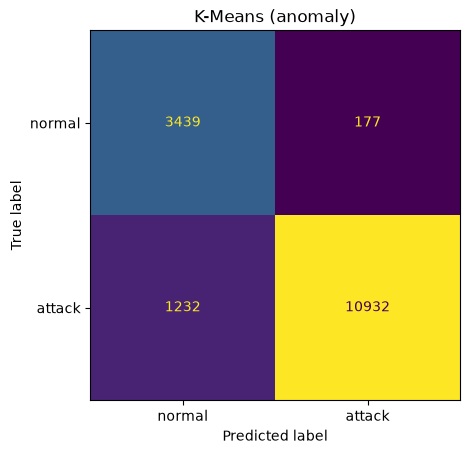

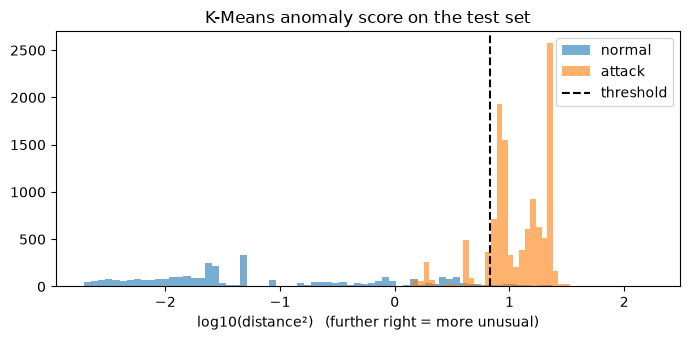

  -> exported to esp32/06_kmeans


In [281]:
K = 16    # number of clusters (typical "kinds" of normal traffic)

# 1) Train on normal traffic only (label 0)
start = time.perf_counter()
km = KMeans(n_clusters=K, n_init=5, random_state=SEED)
km.fit(X_train[y_train == 0])
km_time = time.perf_counter() - start


def km_score(X):
    """Anomaly score = squared distance to the nearest cluster centre."""
    distances = km.transform(X)              # distance to every centre, shape (rows, K)
    return (distances ** 2).min(axis=1)      # keep the nearest one


def km_predict(X):
    """1 (attack) if the score is above the threshold, else 0 (normal)."""
    return (km_score(X) > km_threshold).astype(int)


# 2) Choose the threshold with NORMAL validation data
#    e.g. 95th percentile -> 95% of normal traffic stays below it (~5% false alarms)
normal_val_scores = km_score(X_val[y_val == 0])
km_threshold = float(np.percentile(normal_val_scores, ANOMALY_PERCENTILE))

# 3) Evaluate on the test set
y_pred   = km_predict(X_test)
test_scores = km_score(X_test)
km_auc   = roc_auc_score(y_test, test_scores)   # how well the score separates the classes (1.0 = perfect)

# 4) Write the model as C arrays: the K centres + the threshold
km_h  = f"#define KM_K {K}\n"
km_h += f"static const float KM_THRESHOLD = {c_float(km_threshold)};\n\n"
km_h += c_array("KM_CENTROIDS", km.cluster_centers_, "float")

km_size = (km.cluster_centers_.size + 1) * 4      # K x 20 centres + 1 threshold

evaluate("K-Means (anomaly)", y_test, y_pred, km_time, km_predict, km_size,
         extra={"threshold": km_threshold, "roc_auc": km_auc})
print(f"ROC-AUC = {km_auc:.3f}")
plot_confusion_matrix("K-Means (anomaly)")

# 5) Plot: how the anomaly scores of normal vs attack traffic look
plt.figure(figsize=(7, 3.5))
plt.hist(np.log10(test_scores[y_test == 0] + 1e-6), bins=80, alpha=0.6, label="normal")
plt.hist(np.log10(test_scores[y_test == 1] + 1e-6), bins=80, alpha=0.6, label="attack")
plt.axvline(np.log10(km_threshold), color="k", linestyle="--", label="threshold")
plt.xlabel("log10(distance²)   (further right = more unusual)")
plt.title("K-Means anomaly score on the test set")
plt.legend()
plt.tight_layout()
plt.show()

# 6) Write the files into esp32/06_kmeans
export_project("06_kmeans", "KMeansAnomaly", km_h, y_pred)

## 6. Neural networks (TensorFlow/Keras → int8 TensorFlow Lite Micro)

In [282]:
# ---------------------------------------------------------------
# 6.0 Helpers for the neural networks
# ---------------------------------------------------------------
# The networks are trained in Keras (float32), then converted to int8
# TensorFlow Lite so they fit on the ESP32 and run with TFLite Micro.


# ---- 1) Training --------------------------------------------------------
def train_keras(model, X, y, X_val, y_val, loss, class_weight=None):
    """Train a Keras model and stop early when the validation loss stops improving."""
    metrics = [] if loss == "mse" else ["accuracy"]          # the autoencoder has no accuracy
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss=loss, metrics=metrics)

    stop_early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                               restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(X, y, validation_data=(X_val, y_val),
                        epochs=NN_EPOCHS, batch_size=NN_BATCH,
                        class_weight=class_weight, callbacks=[stop_early], verbose=0)
    train_time = time.perf_counter() - start

    epochs = len(history.history["loss"])
    print(f"trained {epochs} epochs in {train_time:.1f}s, "
          f"best val_loss = {min(history.history['val_loss']):.4f}")
    return history, train_time


def plot_history(history, title):
    """Plot the loss (and accuracy) per epoch for training and validation data."""
    has_accuracy = "accuracy" in history.history
    fig, axes = plt.subplots(1, 2 if has_accuracy else 1, figsize=(10, 3))
    axes = np.atleast_1d(axes)

    axes[0].plot(history.history["loss"], label="train")
    axes[0].plot(history.history["val_loss"], label="validation")
    axes[0].set_title(f"{title} - loss")
    axes[0].legend()

    if has_accuracy:
        axes[1].plot(history.history["accuracy"], label="train")
        axes[1].plot(history.history["val_accuracy"], label="validation")
        axes[1].set_title(f"{title} - accuracy")
        axes[1].legend()

    plt.tight_layout()
    plt.show()


# ---- 2) Convert to int8 TensorFlow Lite ---------------------------------
def to_int8_tflite(model, X_example):
    """Convert a trained Keras model to a fully int8-quantised .tflite model.

    The converter needs some example inputs (the "representative dataset")
    to find out the value range of every layer -> 300 training samples.
    """
    input_shape = tuple(model.input_shape[1:])                # e.g. (20,) or (20, 1)

    def representative_dataset():
        rows = np.random.RandomState(SEED).choice(len(X_example), 300, replace=False)
        for i in rows:
            yield [X_example[i].reshape((1,) + input_shape).astype(np.float32)]

    # rebuild the model with a fixed batch size of 1 (the ESP32 handles one sample
    # at a time) -> fixed shapes, so TFLite needs fewer and simpler operations
    inp = keras.Input(batch_shape=(1,) + input_shape)
    fixed_model = keras.Model(inp, model(inp))

    converter = tf.lite.TFLiteConverter.from_keras_model(fixed_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_dataset
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]  # int8 only
    converter.inference_input_type = tf.int8      # the ESP32 gives int8 input
    converter.inference_output_type = tf.int8     # and gets int8 output
    return converter.convert()                    # the .tflite file as bytes


# ---- 3) Run the int8 model in Python, the same way the ESP32 does -------
class TFLiteModel:
    """Runs an int8 .tflite model like main/model.cpp on the ESP32, so the
    accuracy we report is the accuracy of the model that really runs on the board."""

    def __init__(self, tflite_bytes):
        # BUILTIN_REF = the plain reference maths, closest to TFLite Micro
        self.interpreter = tf.lite.Interpreter(
            model_content=tflite_bytes,
            experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_REF)
        self.interpreter.allocate_tensors()
        self.input  = self.interpreter.get_input_details()[0]
        self.output = self.interpreter.get_output_details()[0]

        # int8 value = round(float / scale) + zero_point
        self.in_scale,  self.in_zero  = self.input["quantization"]
        self.out_scale, self.out_zero = self.output["quantization"]

        # which TFLite operations the model uses (needed for the ESP32 code)
        self.ops = sorted({op["op_name"] for op in self.interpreter._get_ops_details()})

    def to_int8(self, X):
        """float -> int8, rounding exactly like lroundf() in C."""
        v = X / self.in_scale
        rounded = np.sign(v) * np.floor(np.abs(v) + 0.5)
        return np.clip(rounded + self.in_zero, -128, 127).astype(np.int8)

    def raw_output(self, X):
        """Run the model on every row of X, return the int8 outputs."""
        X_int8 = self.to_int8(X)
        n_outputs = self.output["shape"][-1]
        outputs = np.empty((len(X), n_outputs), dtype=np.int8)
        for i in range(len(X)):                                   # one sample at a time
            self.interpreter.set_tensor(self.input["index"], X_int8[i].reshape(self.input["shape"]))
            self.interpreter.invoke()
            outputs[i] = self.interpreter.get_tensor(self.output["index"])[0]
        return outputs

    def to_float(self, out_int8):
        """int8 output -> float."""
        return (out_int8.astype(np.float32) - self.out_zero) * self.out_scale

    def predict(self, X):
        """Class with the highest output (for the classifiers)."""
        return self.raw_output(X).argmax(axis=1)


# ---- 4) Write model_data.h for TFLite Micro ------------------------------
# TFLite Micro only includes the operations you register (saves flash).
# This table translates the TFLite operation name to the C++ function.
TFLM_OPS = {
    "FULLY_CONNECTED": "AddFullyConnected",   # Dense layer
    "CONV_2D":         "AddConv2D",           # Conv1D becomes Conv2D in TFLite
    "MAX_POOL_2D":     "AddMaxPool2D",
    "MEAN":            "AddMean",             # GlobalAveragePooling
    "RESHAPE":         "AddReshape",
    "EXPAND_DIMS":     "AddExpandDims",
    "SQUEEZE":         "AddSqueeze",
    "SOFTMAX":         "AddSoftmax",
    "LOGISTIC":        "AddLogistic",         # sigmoid
    "RELU":            "AddRelu",
    "QUANTIZE":        "AddQuantize",
    "DEQUANTIZE":      "AddDequantize",
}


def tflm_model_h(tflite_bytes, tfl, arena_kb, extra=""):
    """C code for model_data.h: the .tflite bytes + which ops to register."""
    missing = [op for op in tfl.ops if op not in TFLM_OPS]
    if missing:
        raise ValueError(f"add these operations to TFLM_OPS: {missing}")

    register = " ".join(f"(r).{TFLM_OPS[op]}();" for op in tfl.ops)

    h  = f"// operations used by the model: {', '.join(tfl.ops)}\n"
    h += f"#define MODEL_OP_COUNT {len(tfl.ops)}\n"
    h += f"#define MODEL_REGISTER_OPS(r) do {{ {register} }} while (0)\n"
    h += "// working memory for TFLite Micro (the board prints how much is really used)\n"
    h += f"#define TENSOR_ARENA_SIZE ({arena_kb} * 1024)\n"
    h += extra + "\n"
    h += c_array("g_model", np.frombuffer(tflite_bytes, dtype=np.uint8), "unsigned char",
                 per_line=16, align=True)
    h += f"static const unsigned int g_model_len = {len(tflite_bytes)};\n"
    return h

### 6.1 MLP (multilayer perceptron)

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_39 (Dense)                │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,234 (4.82 KB)

 Trainable params: 1,234 (4.82 KB)

 Non-trainable params: 0 (0.00 B)

trained 30 epochs in 5.9s, best val_loss = 0.0237


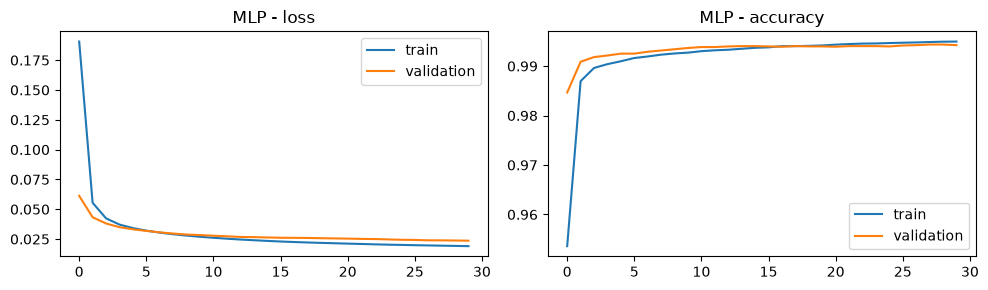

INFO:tensorflow:Assets written to: /tmp/tmpxlght640/assets


INFO:tensorflow:Assets written to: /tmp/tmpxlght640/assets


Saved artifact at '/tmp/tmpxlght640'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 20), dtype=tf.float32, name='keras_tensor_124')
Output Type:
  TensorSpec(shape=(1, 2), dtype=tf.float32, name=None)
Captures:
  140485116859920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484970976400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484970971984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140485116856272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140485116859344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140485116865296: TensorSpec(shape=(), dtype=tf.resource, name=None)
MLP (int8): accuracy=0.9954  precision=0.9988  recall=0.9952  F1=0.9970  size=5.1 KB
compression: float32 accuracy 0.9954 -> int8 accuracy 0.9954
weights: float32 4936 bytes -> int8 ~1234 bytes (the .tflite file is 5176 bytes incl. the network description)
TFLite operations used: ['FULLY_CONNECTED', 'SOFTM

/home/berat/Documents/Master/Models/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792035601.634394  150286 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792035601.634406  150286 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792035601.634476  150286 reader.cc:83] Reading SavedModel from: /tmp/tmpxlght640
I0000 00:00:1792035601.634732  150286 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792035601.634736  150286 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpxlght640
I0000 00:00:1792035601.636226  150286 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792035601.646036  150286 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpxlght640
I0000 00:00:1792035601.649038  150286 loader.cc:471] SavedModel

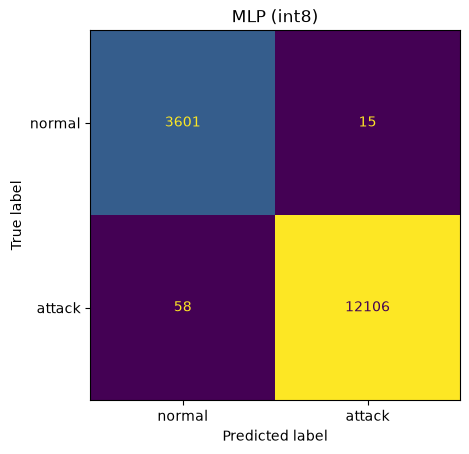

  -> exported to esp32/07_mlp


In [283]:
mlp = keras.Sequential([
    keras.Input(shape=(N_FEATURES,)),                    # 20 preprocessed features
    keras.layers.Dense(32, activation="relu"),           # hidden layer 1
    keras.layers.Dense(16, activation="relu"),           # hidden layer 2
    keras.layers.Dense(N_CLASSES, activation="softmax"), # probability of normal / attack
], name="mlp")
mlp.summary()

# 2) Train (float32) and show the learning curves
history, mlp_time = train_keras(mlp, X_train, y_train, X_val, y_val,
                                loss="sparse_categorical_crossentropy",   # labels are 0/1, not one-hot
                                class_weight=CLASS_WEIGHT)
plot_history(history, "MLP")

# accuracy of the normal float32 model (before compression)
float_pred = mlp.predict(X_test, verbose=0).argmax(axis=1)
float_acc  = accuracy_score(y_test, float_pred)

# 3) Compress to int8 and evaluate the int8 model (= what runs on the ESP32)
mlp_bytes = to_int8_tflite(mlp, X_train)
mlp_tfl   = TFLiteModel(mlp_bytes)
y_pred    = mlp_tfl.predict(X_test)
int8_acc  = accuracy_score(y_test, y_pred)

evaluate("MLP (int8)", y_test, y_pred, mlp_time, mlp_tfl.predict, len(mlp_bytes),
         extra={"float32_accuracy": float_acc, "params": mlp.count_params()})
print(f"compression: float32 accuracy {float_acc:.4f} -> int8 accuracy {int8_acc:.4f}")
print(f"weights: float32 {mlp.count_params() * 4} bytes -> int8 ~{mlp.count_params()} bytes "
      f"(the .tflite file is {len(mlp_bytes)} bytes incl. the network description)")
print(f"TFLite operations used: {mlp_tfl.ops}")
plot_confusion_matrix("MLP (int8)")

# 4) Write the files into esp32/07_mlp
mlp_h = tflm_model_h(mlp_bytes, mlp_tfl, arena_kb=16,
                     extra="#define NN_IS_AUTOENCODER 0\n")   # 0 = classifier
export_project("07_mlp", "MLP_int8", mlp_h, y_pred)

### 6.2 1D-CNN

Model: "cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)               │ (None, 20, 8)          │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 10, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 10, 16)         │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_3      │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 738 (2.88 KB)

 Trainable params: 738 (2.88 KB)

 Non-trainable params: 0 (0.00 B)

trained 30 epochs in 9.4s, best val_loss = 0.0318


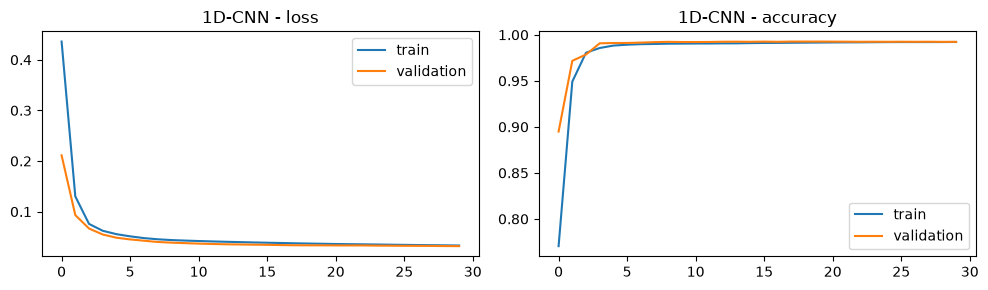

INFO:tensorflow:Assets written to: /tmp/tmp2liid47c/assets


INFO:tensorflow:Assets written to: /tmp/tmp2liid47c/assets


Saved artifact at '/tmp/tmp2liid47c'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 20, 1), dtype=tf.float32, name='keras_tensor_135')
Output Type:
  TensorSpec(shape=(1, 2), dtype=tf.float32, name=None)
Captures:
  140484961829328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484961836048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140485116855312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484280685712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484280680912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484280695696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484280696464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484280686480: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/berat/Documents/Master/Models/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792035611.696218  150286 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792035611.696227  150286 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792035611.696298  150286 reader.cc:83] Reading SavedModel from: /tmp/tmp2liid47c
I0000 00:00:1792035611.696545  150286 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792035611.696548  150286 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp2liid47c
I0000 00:00:1792035611.698284  150286 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792035611.710308  150286 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp2liid47c
I0000 00:00:1792035611.714015  150286 loader.cc:471] SavedModel

1D-CNN (int8): accuracy=0.9929  precision=0.9980  recall=0.9928  F1=0.9954  size=6.9 KB
compression: float32 accuracy 0.9935 -> int8 accuracy 0.9929
weights: float32 2952 bytes -> int8 ~738 bytes (the .tflite file is 7024 bytes incl. the network description)
TFLite operations used: ['CONV_2D', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'MEAN', 'RESHAPE', 'SOFTMAX']


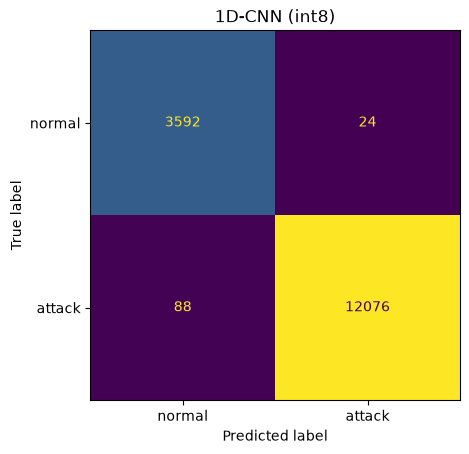

  -> exported to esp32/08_cnn1d


In [284]:
cnn = keras.Sequential([
    keras.Input(shape=(N_FEATURES, 1)),              # 20 values, 1 channel
    keras.layers.Conv1D(8, 3, padding="same", activation="relu"),   # 8 filters, 3 wide
    keras.layers.MaxPooling1D(2),                    # keep the max of every 2 values -> 10 values
    keras.layers.Conv1D(16, 3, padding="same", activation="relu"),  # 16 filters, 3 wide
    keras.layers.GlobalAveragePooling1D(),           # average over the 10 positions -> 16 numbers
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(N_CLASSES, activation="softmax"),            # normal / attack
], name="cnn1d")
cnn.summary()

# the CNN needs shape (rows, 20, 1) instead of (rows, 20); the numbers are the same
X_train_cnn = X_train.reshape(-1, N_FEATURES, 1)
X_val_cnn   = X_val.reshape(-1, N_FEATURES, 1)
X_test_cnn  = X_test.reshape(-1, N_FEATURES, 1)

# 2) Train (float32) and show the learning curves
history, cnn_time = train_keras(cnn, X_train_cnn, y_train, X_val_cnn, y_val,
                                loss="sparse_categorical_crossentropy",
                                class_weight=CLASS_WEIGHT)
plot_history(history, "1D-CNN")

# accuracy of the normal float32 model (before compression)
float_pred = cnn.predict(X_test_cnn, verbose=0).argmax(axis=1)
float_acc  = accuracy_score(y_test, float_pred)

# 3) Compress to int8 and evaluate the int8 model (= what runs on the ESP32)
cnn_bytes = to_int8_tflite(cnn, X_train)       # reshapes to (1, 20, 1) by itself
cnn_tfl   = TFLiteModel(cnn_bytes)
y_pred    = cnn_tfl.predict(X_test)
int8_acc  = accuracy_score(y_test, y_pred)

evaluate("1D-CNN (int8)", y_test, y_pred, cnn_time, cnn_tfl.predict, len(cnn_bytes),
         extra={"float32_accuracy": float_acc, "params": cnn.count_params()})
print(f"compression: float32 accuracy {float_acc:.4f} -> int8 accuracy {int8_acc:.4f}")
print(f"weights: float32 {cnn.count_params() * 4} bytes -> int8 ~{cnn.count_params()} bytes "
      f"(the .tflite file is {len(cnn_bytes)} bytes incl. the network description)")
print(f"TFLite operations used: {cnn_tfl.ops}")
plot_confusion_matrix("1D-CNN (int8)")

# 4) Write the files into esp32/08_cnn1d
#    (a CNN needs more working memory than the MLP -> 24 KB arena)
cnn_h = tflm_model_h(cnn_bytes, cnn_tfl, arena_kb=24,
                     extra="#define NN_IS_AUTOENCODER 0\n")
export_project("08_cnn1d", "CNN1D_int8", cnn_h, y_pred)

### 6.3 Autoencoder anomaly detector (unsupervised)

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_44 (Dense)                │ (None, 16)             │           336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 20)             │           340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 956 (3.73 KB)

 Trainable params: 956 (3.73 KB)

 Non-trainable params: 0 (0.00 B)

trained 30 epochs in 2.3s, best val_loss = 0.0590


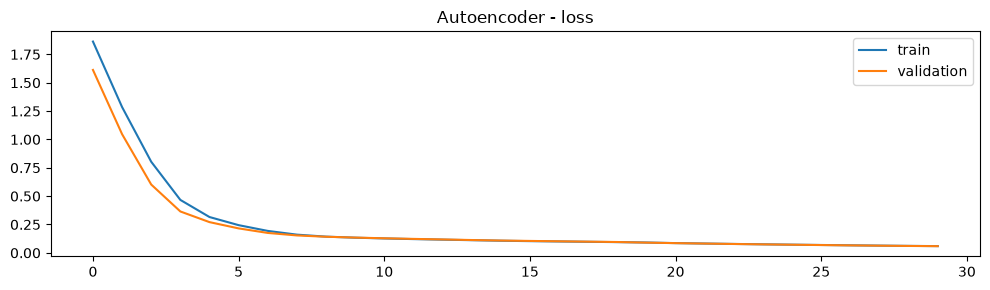

INFO:tensorflow:Assets written to: /tmp/tmp6mw6m4yz/assets


INFO:tensorflow:Assets written to: /tmp/tmp6mw6m4yz/assets


Saved artifact at '/tmp/tmp6mw6m4yz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 20), dtype=tf.float32, name='keras_tensor_147')
Output Type:
  TensorSpec(shape=(1, 20), dtype=tf.float32, name=None)
Captures:
  140484280690320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484963190160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484286292688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484286287888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484286298640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484286286928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484286297104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140484286285584: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/berat/Documents/Master/Models/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792035614.430266  150286 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792035614.430276  150286 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792035614.430354  150286 reader.cc:83] Reading SavedModel from: /tmp/tmp6mw6m4yz
I0000 00:00:1792035614.430669  150286 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792035614.430676  150286 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp6mw6m4yz
I0000 00:00:1792035614.432871  150286 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792035614.445496  150286 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp6mw6m4yz
I0000 00:00:1792035614.448883  150286 loader.cc:471] SavedModel

Autoencoder (int8, anomaly): accuracy=0.5301  precision=0.9712  recall=0.4023  F1=0.5690  size=5.5 KB
compression: float32 accuracy 0.5383 -> int8 accuracy 0.5301
ROC-AUC = 0.930


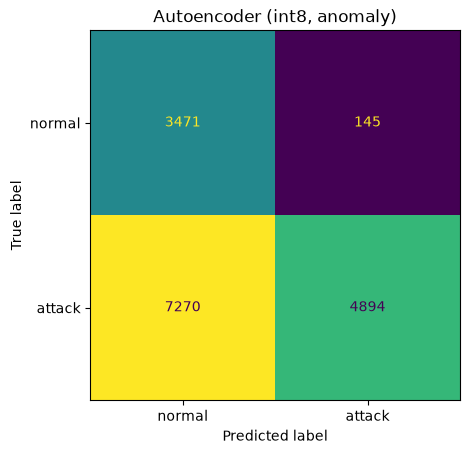

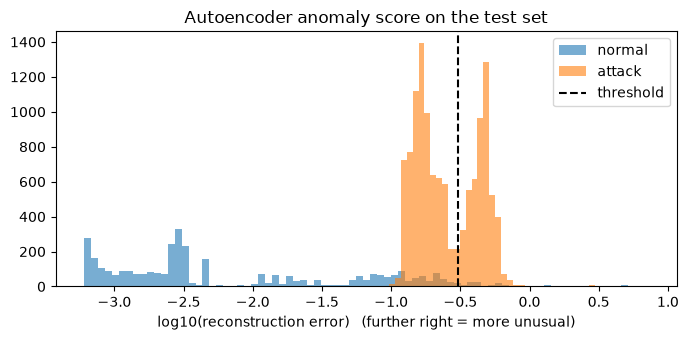

  -> exported to esp32/09_autoencoder


In [285]:
ae = keras.Sequential([
    keras.Input(shape=(N_FEATURES,)),
    keras.layers.Dense(16, activation="relu"),             # encoder
    keras.layers.Dense(8,  activation="relu"),             # bottleneck: 20 -> 8 numbers
    keras.layers.Dense(16, activation="relu"),             # decoder
    keras.layers.Dense(N_FEATURES, activation="linear"),   # rebuilt 20 features
], name="autoencoder")
ae.summary()

# 2) Train on normal traffic only: input = target (it must copy itself)
X_train_normal = X_train[y_train == 0]
X_val_normal   = X_val[y_val == 0]
history, ae_time = train_keras(ae, X_train_normal, X_train_normal,
                               X_val_normal, X_val_normal, loss="mse")
plot_history(history, "Autoencoder")

# 3) Compress to int8 (= what runs on the ESP32)
ae_bytes = to_int8_tflite(ae, X_train_normal)
ae_tfl   = TFLiteModel(ae_bytes)


def ae_score(X):
    """Anomaly score = reconstruction error of the int8 model (same as on the ESP32)."""
    rebuilt = ae_tfl.to_float(ae_tfl.raw_output(X))
    return ((rebuilt - X) ** 2).mean(axis=1)


def ae_predict(X):
    """1 (attack) if the reconstruction error is above the threshold, else 0 (normal)."""
    return (ae_score(X) > ae_threshold).astype(int)


# 4) Choose the threshold with NORMAL validation data (computed with the int8 model,
#    so it matches the ESP32 exactly)
ae_threshold = float(np.percentile(ae_score(X_val_normal), ANOMALY_PERCENTILE))

# 5) Evaluate on the test set
y_pred      = ae_predict(X_test)
test_scores = ae_score(X_test)
ae_auc      = roc_auc_score(y_test, test_scores)

# for comparison: the same detector with the float32 model (before compression)
def float_error(X):
    return ((ae.predict(X, verbose=0) - X) ** 2).mean(axis=1)

float_threshold = np.percentile(float_error(X_val_normal), ANOMALY_PERCENTILE)
float_acc = accuracy_score(y_test, (float_error(X_test) > float_threshold).astype(int))

evaluate("Autoencoder (int8, anomaly)", y_test, y_pred, ae_time, ae_predict, len(ae_bytes),
         extra={"float32_accuracy": float_acc, "threshold": ae_threshold,
                "roc_auc": ae_auc, "params": ae.count_params()})
print(f"compression: float32 accuracy {float_acc:.4f} -> int8 accuracy {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC = {ae_auc:.3f}")
plot_confusion_matrix("Autoencoder (int8, anomaly)")

# 6) Plot: reconstruction error of normal vs attack traffic
plt.figure(figsize=(7, 3.5))
plt.hist(np.log10(test_scores[y_test == 0] + 1e-6), bins=80, alpha=0.6, label="normal")
plt.hist(np.log10(test_scores[y_test == 1] + 1e-6), bins=80, alpha=0.6, label="attack")
plt.axvline(np.log10(ae_threshold), color="k", linestyle="--", label="threshold")
plt.xlabel("log10(reconstruction error)   (further right = more unusual)")
plt.title("Autoencoder anomaly score on the test set")
plt.legend()
plt.tight_layout()
plt.show()

# 7) Write the files into esp32/09_autoencoder
ae_extra  = "#define NN_IS_AUTOENCODER 1\n"                               # 1 = anomaly detector
ae_extra += f"static const float AE_THRESHOLD = {c_float(ae_threshold)};\n"
ae_h = tflm_model_h(ae_bytes, ae_tfl, arena_kb=16, extra=ae_extra)
export_project("09_autoencoder", "Autoencoder_int8", ae_h, y_pred)

## 7. Comparison

In [286]:
table = pd.DataFrame(results).set_index("model")

# columns in a logical order; a column only appears if at least one model has it
# (e.g. n_nodes only exists for the trees, roc_auc only for the anomaly detectors)
column_order = ["accuracy", "precision", "recall", "f1", "roc_auc",   # quality
                "float32_accuracy",                                  # NN before int8 compression
                "size_kb", "pc_infer_us", "train_time_s",            # cost
                "n_nodes", "depth", "params", "n_support_vectors",   # model size details
                "threshold"]                                         # anomaly detectors
columns = [col for col in column_order if col in table.columns]
table = table[columns]

# save for the thesis (open it in Excel / LibreOffice or use it for plots)
table.to_csv(RESULTS_DIR / "pc_results.csv")
print("saved", RESULTS_DIR / "pc_results.csv")

# show it: 4 decimals, empty cells instead of NaN, best F1 in dark green
display(table.style
        .format(precision=4, na_rep="")
        .background_gradient(subset=["f1"], cmap="Greens"))

saved results/pc_results.csv


,accuracy,precision,recall,f1,roc_auc,float32_accuracy,size_kb,pc_infer_us,train_time_s,n_nodes,depth,params,n_support_vectors,threshold
model,,,,,,,,,,,,,,
Decision Tree,0.9970,0.9984,0.9977,0.9980,,,3.4590,0.0652,0.1293,253.0000,10.0000,,,
Random Forest,0.9958,0.9974,0.9972,0.9973,,,29.5000,5.7509,0.0591,2152.0000,,,,
Logistic Regression,0.9782,0.9902,0.9814,0.9858,,,0.0820,0.0699,0.7558,,,,,
Linear SVM,0.9774,0.9902,0.9804,0.9853,,,0.0820,0.0819,0.5510,,,,,
RBF SVM,0.9867,0.9968,0.9859,0.9913,,,41.1055,12.9436,0.1116,,,,501.0000,
Naive Bayes,0.8798,0.9394,0.9023,0.9205,,,0.3203,0.1371,0.0101,,,,,
K-Means (anomaly),0.9107,0.9841,0.8987,0.9395,0.9642,,1.2539,0.2347,0.0549,,,,,6.7554
MLP (int8),0.9954,0.9988,0.9952,0.9970,,0.9954,5.0547,2.3017,5.8963,,,1234.0000,,
1D-CNN (int8),0.9929,0.9980,0.9928,0.9954,,0.9935,6.8594,8.3012,9.3730,,,738.0000,,


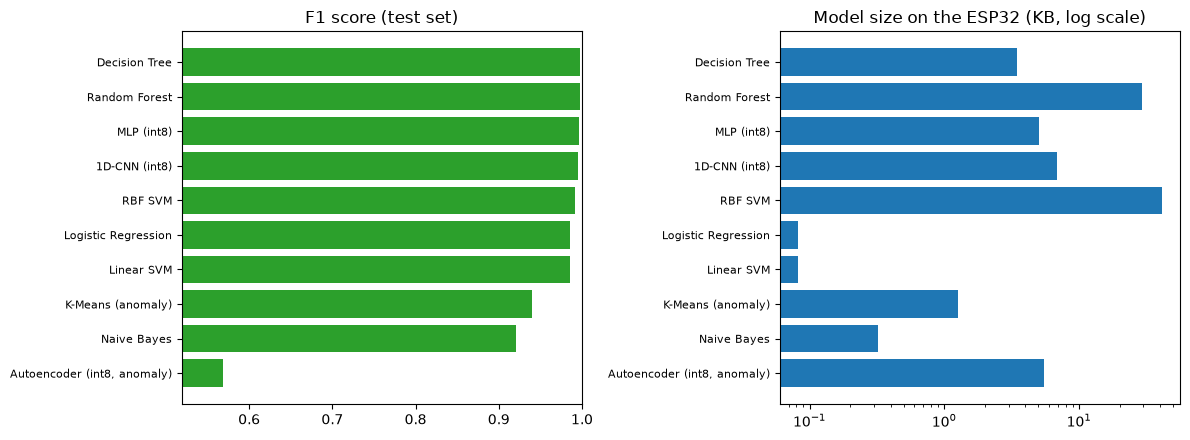

In [288]:
ranked = table.sort_values("f1")

fig, (ax_f1, ax_size) = plt.subplots(1, 2, figsize=(12, 4.5))

# 1) F1 score per model
ax_f1.barh(ranked.index, ranked["f1"], color="tab:green")
ax_f1.set_title("F1 score (test set)")
ax_f1.set_xlim(max(0, ranked["f1"].min() - 0.05), 1)   # zoom in so small differences are visible

# 2) Size on the ESP32 per model (log scale: from 0.08 KB to 40 KB)
ax_size.barh(ranked.index, ranked["size_kb"], color="tab:blue")
ax_size.set_xscale("log")
ax_size.set_title("Model size on the ESP32 (KB, log scale)")

ax_f1.tick_params(axis="y", labelsize=8)     # smaller model names so they fit
ax_size.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparison.png", dpi=150)   # for the thesis
plt.show()

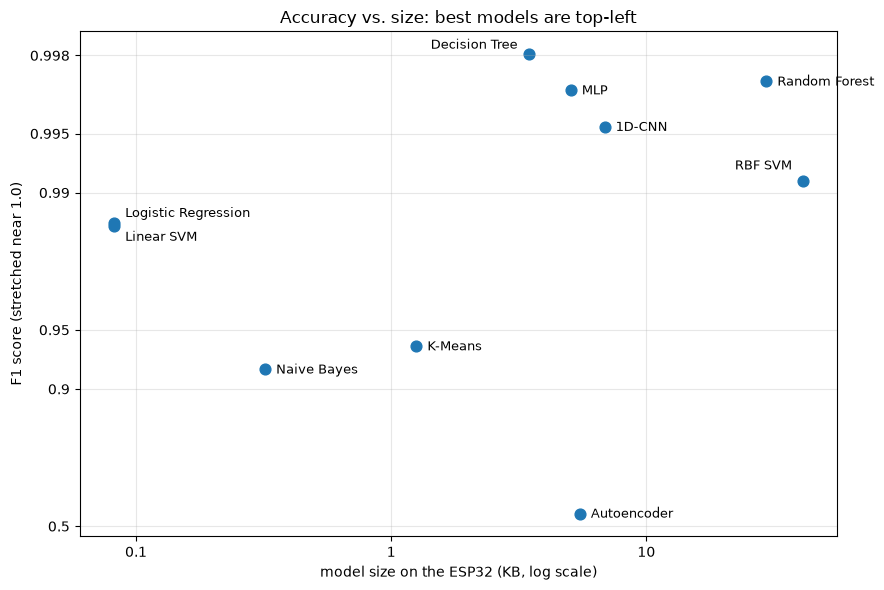

In [ ]:
# 7.2 Accuracy vs. size trade-off
fig, ax = plt.subplots(figsize=(9, 6))

error = 1 - table["f1"]
ax.scatter(table["size_kb"], error, s=60)

# name next to every dot; a few need another spot so they don't overlap
offsets = {"Decision Tree": (-8, 4), "Logistic Regression": (8, 4),
           "Linear SVM": (8, -11), "RBF SVM": (-8, 8)}
for name in table.index:
    dx, dy = offsets.get(name, (8, -3))
    short_name = name.split(" (")[0]                 # "MLP (int8)" -> "MLP"
    ax.annotate(short_name, (table.loc[name, "size_kb"], error[name]),
                xytext=(dx, dy), textcoords="offset points", fontsize=9,
                ha="right" if dx < 0 else "left")

ax.set_xscale("log")
ax.set_yscale("log")
ax.invert_yaxis()                                    # high F1 at the top
ax.minorticks_off()
ax.set_xticks([0.1, 1, 10], ["0.1", "1", "10"])
f1_values = [0.5, 0.9, 0.95, 0.99, 0.995, 0.998]
ax.set_yticks([1 - f for f in f1_values], [str(f) for f in f1_values])

ax.set_xlabel("model size on the ESP32 (KB, log scale)")
ax.set_ylabel("F1 score (stretched near 1.0)")
ax.set_title("Accuracy vs. size: best models are top-left")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "tradeoff.png", dpi=150)
plt.show()